=== HASIL EVALUASI MODEL ===
Akurasi Model: 75.00%

Confusion Matrix (Teks):
[[2 0]
 [1 1]]

Laporan Klasifikasi Lengkap:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



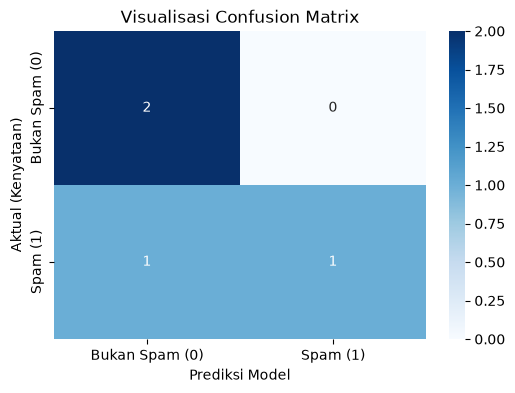

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# 1. Menyiapkan Dataset Menggunakan Pandas DataFrame
data = {
 'jumlah_kata_sensitif': [
 8, 6, 10, 7, 9, 12, 11, 8, 7, 10, # 10 data Spam (1)
 1, 0, 1, 2, 0, 1, 0, 2, 1, 0 # 10 data Normal (0)
 ],
 'panjang_email': [
 150, 90, 200, 110, 180, 250, 210, 160, 130, 190, # Panjang email spam
 80, 60, 95, 70, 50, 85, 65, 90, 75, 55 # Panjang email normal
 ],
 'is_spam': [
 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, # Label Spam
 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 # Label Normal
 ]
}
df = pd.DataFrame(data)
# Memisahkan Fitur (X) dan Target (y) dari DataFrame
X = df[['jumlah_kata_sensitif', 'panjang_email']]
y = df['is_spam']
# 2. Membagi Data menjadi Data Training dan Data Testing (Proporsi 80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 3. Membuat Objek Model Logistic Regression dan Melatih Model
model = LogisticRegression()
model.fit(X_train, y_train)
# 4. Melakukan Prediksi Menggunakan Data Testing
y_pred = model.predict(X_test)
# 5. Evaluasi Performa Model & Perhitungan Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("=== HASIL EVALUASI MODEL ===")
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Confusion Matrix (Teks):")
print(cm)
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred))
# 6. VISUALISASI CONFUSION MATRIX
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
 xticklabels=['Bukan Spam (0)', 'Spam (1)'],
 yticklabels=['Bukan Spam (0)', 'Spam (1)'])
plt.ylabel('Aktual (Kenyataan)')
plt.xlabel('Prediksi Model')
plt.title('Visualisasi Confusion Matrix')
plt.show()

C:\Users\lenovo\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


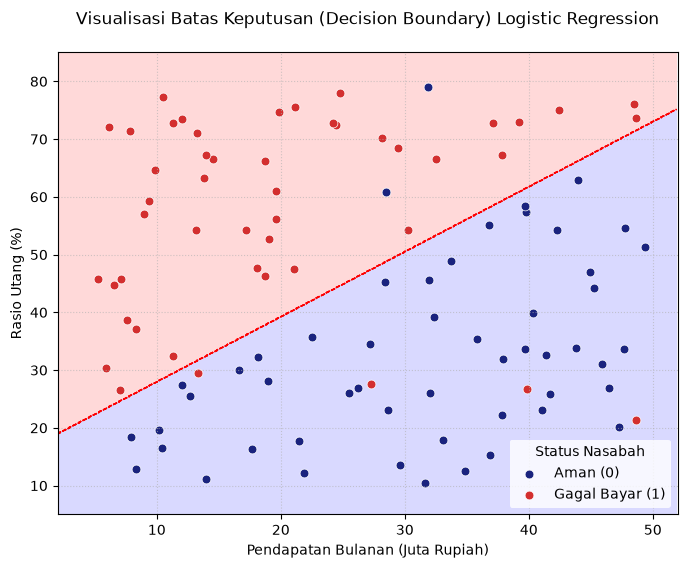

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# 1. Menghasilkan Data Acak yang Sesuai dengan Pola Grafik Dosen
np.random.seed(42)
n_samples = 100

# Fitur 1: Pendapatan Bulanan (Rentang 5 - 50 Juta)
pendapatan = np.random.uniform(5, 50, n_samples)
# Fitur 2: Rasio Utang (Rentang 10% - 80%)
rasio_utang = np.random.uniform(10, 80, n_samples)

# Membuat Label Target (0: Aman, 1: Gagal Bayar) berdasarkan batas garis linear miring
# Pola: Rasio utang tinggi & pendapatan rendah cenderung Gagal Bayar (1)
z_pola = 0.1 * pendapatan - 0.08 * rasio_utang + 1
probabilitas = 1 / (1 + np.exp(-z_pola))
is_gagal_bayar = (probabilitas < 0.5).astype(int)

# Tambahkan sedikit noise acak agar beberapa titik menyeberang (seperti grafik asli)
noise_idx = np.random.choice(n_samples, size=5, replace=False)
is_gagal_bayar[noise_idx] = 1 - is_gagal_bayar[noise_idx]

# Satukan ke dalam DataFrame
df_bank = pd.DataFrame({
    'Pendapatan Bulanan': pendapatan,
    'Rasio Utang': rasio_utang,
    'Status Nasabah': is_gagal_bayar
})

X = df_bank[['Pendapatan Bulanan', 'Rasio Utang']]
y = df_bank['Status Nasabah']

# 2. Melatih Model Logistic Regression
model_bank = LogisticRegression()
model_bank.fit(X, y)

# 3. Membuat Grid Koordinat untuk Mewarnai Area Batas Keputusan
x_min, x_max = 2, 52
y_min, y_max = 5, 85
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

# Prediksi status untuk setiap titik di dalam grid koordinat
Z = model_bank.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. PROSES VISUALISASI GRAFIK
plt.figure(figsize=(8, 6))

# Mewarnai Area Latar Belakang (Merah Muda untuk Gagal Bayar, Biru Muda untuk Aman)
# Menggunakan nilai alpha rendah agar transparan dan warna pastel sesuai modul
plt.contourf(xx, yy, Z, alpha=0.15, levels=[-1, 0, 1], colors=['blue', 'red'])
plt.contour(xx, yy, Z, colors='red', linewidths=0.8, linestyles='--') # Garis batas putus-putus

# Memisahkan data untuk plot titik sebaran (Scatter Plot)
aman = df_bank[df_bank['Status Nasabah'] == 0]
gagal = df_bank[df_bank['Status Nasabah'] == 1]

# Plot titik Nasabah Aman (Warna Biru Tua)
plt.scatter(aman['Pendapatan Bulanan'], aman['Rasio Utang'], 
            color='#1a237e', edgecolors='white', linewidths=0.5, label='Aman (0)', s=40)

# Plot titik Nasabah Gagal Bayar (Warna Merah)
plt.scatter(gagal['Pendapatan Bulanan'], gagal['Rasio Utang'], 
            color='#d32f2f', edgecolors='white', linewidths=0.5, label='Gagal Bayar (1)', s=40)

# Mengatur Kelengkapan Atribut Grafik Sesuai Gambar Modul
plt.title('Visualisasi Batas Keputusan (Decision Boundary) Logistic Regression\n', fontsize=12)
plt.xlabel('Pendapatan Bulanan (Juta Rupiah)', fontsize=10)
plt.ylabel('Rasio Utang (%)', fontsize=10)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.grid(True, linestyle=':', alpha=0.6)

# Menambahkan Kotak Keterangan (Legend) di Pojok Kanan Bawah
plt.legend(title='Status Nasabah', loc='lower right', frameon=True, facecolor='white', edgecolor='none')

# Menampilkan Grafik
plt.show()

In [5]:
import pandas as pd
data = {
    "Nama": ["Ahmad", "Bobby", "Chandra","Debby","Emanuel","Fitri"],
    "Umur": [25, 30, 35, 17, 45, 33],
    "Kota": ["Bantul", "Lahat", "Pariaman","Jakarta","Semarang","Bandung"]
}
df = pd.DataFrame(data)
df

,Nama,Umur,Kota
0,Ahmad,25,Bantul
1,Bobby,30,Lahat
2,Chandra,35,Pariaman
3,Debby,17,Jakarta
4,Emanuel,45,Semarang
5,Fitri,33,Bandung


In [6]:
import pandas as pd

data = {
    "Nama": ["Ahmad", "Bobby", "Chandra","Debby","Emanuel","Fitri"],
    "Umur": [25, 30, 35, 17, 45, 33],
    "Kota": ["Bantul", "Lahat", "Pariaman","Jakarta","Semarang","Bandung"]
}
# Membuat indeks dengan tipe data string (menggunakan tanda kutip)
df = pd.DataFrame(data, index=['0', '1', '2','3','4','5'])
df

,Nama,Umur,Kota
0,Ahmad,25,Bantul
1,Bobby,30,Lahat
2,Chandra,35,Pariaman
3,Debby,17,Jakarta
4,Emanuel,45,Semarang
5,Fitri,33,Bandung


In [10]:
import pandas as pd
data = {
    "Nama": ["Ahmad", "Bobby", "Chandra","Debby","Emanuel","Fitri"],
    "Umur": [25, 30, 35, 17, 45, 33],
    "Kota": ["Bantul", "Lahat", "Pariaman","Jakarta","Semarang","Bandung"]
}
df = pd.DataFrame(data)
df.to_csv('datapegawai.csv',index=False)

In [12]:
#eksport data ke file
df.to_csv('datapegawai.csv',index=False)

In [13]:
# Import data dari file CSV:.
df_baru = pd.read_csv("datapegawai.csv")

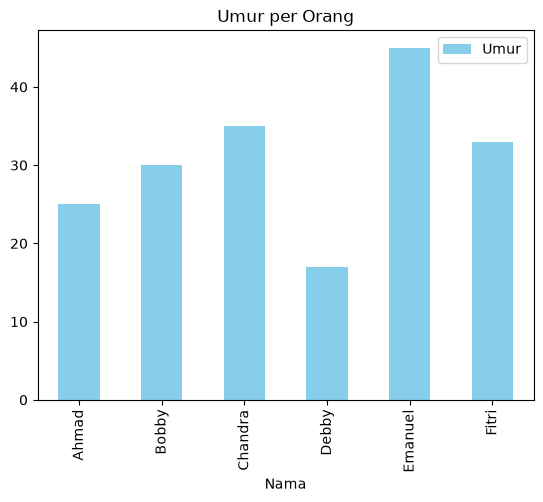

In [15]:
# Dari File CSV: Anda dapat memuat data dari file eksternal dengan mudah.
df = pd.read_csv("datapegawai.csv")

df_baru.plot(kind='bar', x='Nama', y='Umur', color='skyblue', title='Umur per Orang')
plt.show()  # opsional: untuk menampilkan grafik dengan bersih

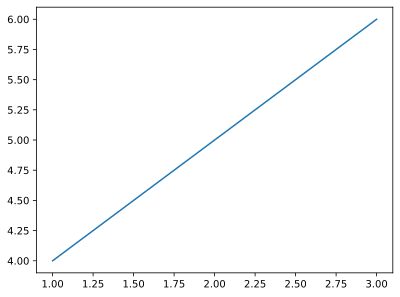

In [16]:
import matplotlib.pyplot as plt
# Tell Jupyter to render inline plots as SVG vector graphics
%config InlineBackend.figure_format = 'svg'

plt.plot([1, 2, 3], [4, 5, 6])
plt.savefig('my_publication_plot.eps')  # Saves sharp EPS to disk
plt.show()  # Displays sharp SVG inline